In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
from sentence_transformers import SentenceTransformer
import pandas as pd
from bertopic import BERTopic
from bertopic.representation import MaximalMarginalRelevance
from bertopic.representation import KeyBERTInspired
from bertopic.vectorizers import ClassTfidfTransformer
from hdbscan import HDBSCAN
import numpy as np

/home/matteo/Documents/Projects/DemocraSci-AM/.venv/lib/python3.12/site-packages/colorspacious/comparison.py:11: SyntaxWarning: invalid escape sequence '\D'
  """Computes the :math:`\Delta E` distance between pairs of colors.


In [3]:
df = pd.read_parquet("clean_paragraphs.parquet")

In [4]:
df

,Speech_ID,Paragraph_ID,TEXT_SPAN,role,language_of_text,name
0,81893,81893_p0,La commission propose de ne pas donner suite à...,President,FR,Bugnon André
1,81894,81894_p0,"Ich möchte Sie nur nochmals bitten, das Result...",For the committee,DE,Widmer Hans
2,81894,81894_p1,"In diesem Sinne bitte ich Sie nochmals, den An...",For the committee,DE,Widmer Hans
3,81895,81895_p0,Der Bundesrat beantragt die Annahme des Postul...,Member of the federal council,DE,Schmid Samuel
4,81895,81895_p1,Aber es geht hier noch um andere Fragen. Es ge...,Member of the federal council,DE,Schmid Samuel
...,...,...,...,...,...,...
303379,288681,288681_p11,"En commission, une minorité avait, quant à ell...",For the committee,FR,Python Valentine
303380,288681,288681_p12,La proposition individuelle Bäumle déposée hie...,For the committee,FR,Python Valentine
303381,288681,288681_p13,En ce qui concerne le cas précis de cette prop...,For the committee,FR,Python Valentine
303382,288681,288681_p14,La majorité de la commission désire prendre en...,For the committee,FR,Python Valentine


In [5]:
EMBEDDING_MODEL = "BAAI/bge-m3" # all-MiniLM-L6-v2
embedder = SentenceTransformer(EMBEDDING_MODEL)

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

In [35]:
embeddings = np.load("paragraph_embeddings.npy")
embeddings.shape

(303384, 1024)

In [36]:
embeddings = embeddings / np.linalg.norm(embeddings, axis=1, keepdims=True)  # Normalize embeddings to unit length

In [37]:
from tqdm import tqdm
from const import DEFAULT_CHAT_PROMPT, DEFAULT_SYSTEM_PROMPT

from bertopic.representation import BaseRepresentation
import llm

class QwenTopic(BaseRepresentation):
    def __init__(
        self,
        model: str = "sdsc-qwen-32b",
        prompt=DEFAULT_CHAT_PROMPT,
        system_prompt=DEFAULT_SYSTEM_PROMPT,
        nr_docs: int = 4,
        diversity: float | None = None,
        **kwargs,
    ):
        """
        Use Qwen to extract topic labels from a set of documents and keywords.

        Arguments:
            model: The Qwen model to use (e.g., "sdsc-qwen-32b")
            prompt: The prompt template to use for Qwen. It should contain [KEYWORDS] and/or [DOCUMENTS] as placeholders.
            system_prompt: The system prompt to set the behavior of the Qwen model.
            nr_docs: The number of documents to pass if a prompt
                 with the `["DOCUMENTS"]` tag is used.
            diversity: Accepts values between 0 and 1. A higher
                   values results in passing more diverse documents
                   whereas lower values passes more similar documents.
        """
        self.model = model
        self.prompt = prompt
        self.system_prompt = system_prompt
        self.nr_docs = nr_docs
        self.diversity = diversity

        self.prompts_ = []

    def extract_topics(self, topic_model, documents, c_tf_idf, topics):
        """Extract topics

        Arguments:
            topic_model: The BERTopic model
            documents: A dataframe of documents with their related topics
            c_tf_idf: The c-TF-IDF matrix
            topics: The candidate topics as calculated with c-TF-IDF

        Returns:
            updated_topics: Updated topic representations
        """
        repr_docs_mappings, _, _, _ = topic_model._extract_representative_docs(
            c_tf_idf, documents, topics, 500, self.nr_docs, self.diversity
        )

        updated_topics = {}
        for topic, docs in tqdm(
            repr_docs_mappings.items(), disable=not topic_model.verbose
        ):
            prompt = self._create_prompt(docs, topic, topics)
            self.prompts_.append(prompt)

            qwen_model = llm.get_model(self.model)
            response = qwen_model.prompt(prompt=prompt, system=self.system_prompt)
            answer = response.text()
            after_thinking = answer.split("</think>")[-1]
            label = after_thinking.replace("topic:", "").strip()
            updated_topics[topic] = [(label, 1)]

        return updated_topics

    def _create_prompt(self, docs, topic, topics):
        keywords = next(zip(*topics[topic]))

        # Use the Default Chat Prompt
        if self.prompt == DEFAULT_CHAT_PROMPT:
            prompt = self.prompt.replace("[KEYWORDS]", ", ".join(keywords))
            prompt = self._replace_documents(prompt, docs)

        # Use a custom prompt that leverages keywords, documents or both using
        # custom tags, namely [KEYWORDS] and [DOCUMENTS] respectively
        else:
            prompt = self.prompt
            if "[KEYWORDS]" in prompt:
                prompt = prompt.replace("[KEYWORDS]", ", ".join(keywords))
            if "[DOCUMENTS]" in prompt:
                prompt = self._replace_documents(prompt, docs)

        return prompt

    @staticmethod
    def _replace_documents(prompt, docs):
        to_replace = ""
        for doc in docs:
            to_replace += f"- {doc}\n"
        prompt = prompt.replace("[DOCUMENTS]", to_replace)
        return prompt

    def get_prompts(self):
        """Returns the prompts used for topic extraction."""
        return self.prompts_


In [38]:
from umap import UMAP
from sklearn.feature_extraction.text import CountVectorizer

umap_model = UMAP(
    n_neighbors=15,
    n_components=5,
    min_dist=0.0,
    metric="cosine",
    random_state=42,
)

hdbscan_model = HDBSCAN(
    min_cluster_size=15,
    metric="euclidean",
    cluster_selection_method="eom",
    prediction_data=True,
)

vectorizer_model = CountVectorizer(stop_words="english", min_df=5, max_df=0.85)

ctfidf_model = ClassTfidfTransformer(reduce_frequent_words=True)

representation_model = {
    "KeyBERT": KeyBERTInspired(),
    "MMR": MaximalMarginalRelevance(diversity=0.3),
    "Qwen": QwenTopic(
        model="sdsc-qwen-32b",
        prompt=DEFAULT_CHAT_PROMPT,
        system_prompt=DEFAULT_SYSTEM_PROMPT,
        nr_docs=3,
    ),
}

topic_model = BERTopic(
    embedding_model=embedder,
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    vectorizer_model=vectorizer_model,
    ctfidf_model=ctfidf_model,
    representation_model=representation_model,
    verbose=True,
)

N_SAMPLES = 5000
df_sample = df.sample(N_SAMPLES, random_state=42).reset_index(drop=True)
texts = df_sample["TEXT_SPAN"].tolist()
embeddings_sample = embeddings[df_sample.index]

# Fit model
topics, probs = topic_model.fit_transform(texts, embeddings=embeddings_sample)

2026-03-27 11:15:25,710 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-03-27 11:15:33,674 - BERTopic - Dimensionality - Completed ✓
2026-03-27 11:15:33,676 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-03-27 11:15:33,859 - BERTopic - Cluster - Completed ✓
2026-03-27 11:15:33,863 - BERTopic - Representation - Fine-tuning topics using representation models.


KeyboardInterrupt: 

In [34]:
topic_model.get_topic_info()

,Topic,Count,Name,Representation,Representative_Docs
0,-1,9,-1_Swiss Parliamentary Motions and Debates,[Swiss Parliamentary Motions and Debates],[Die Mehrheit der Kommission zeigt Verständnis...
1,0,70,0_Social and Health Policy,[Social and Health Policy],"[Jetzt komme ich noch zum letzten Punkt, nämli..."
2,1,21,1_Swiss federal law amendments,[Swiss federal law amendments],[Bei Artikel 22 Absatz 2 ist die Sachlage auch...


In [11]:
topic_model.visualize_topics()

In [12]:
topic_model.visualize_heatmap()


In [13]:
topics_per_class = topic_model.topics_per_class(texts, df_sample["role"])

8it [00:00,  9.21it/s]


In [14]:
topic_model.visualize_topics_per_class(topics_per_class)

In [15]:
from umap.umap_ import UMAP
reduced_embeddings = UMAP(
    n_neighbors=10, n_components=2, min_dist=0.0, metric="cosine", random_state=42
).fit_transform(embeddings_sample)

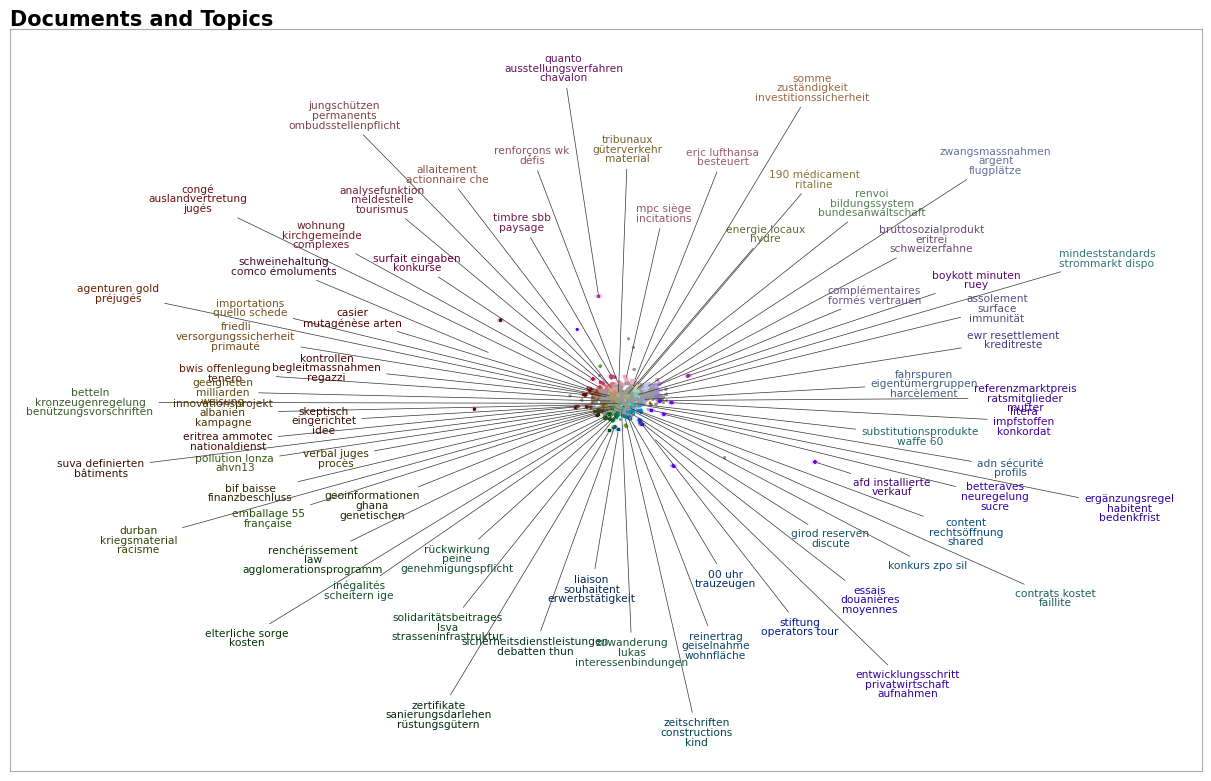

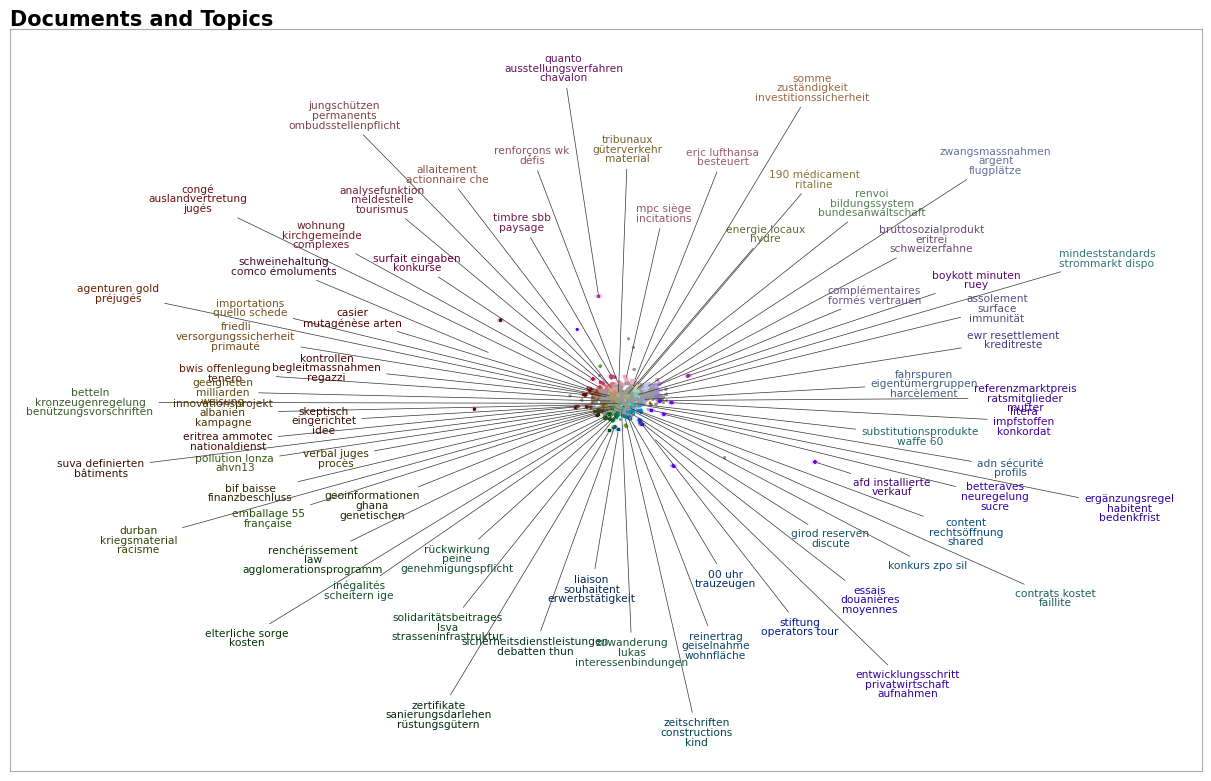

In [16]:
topic_model.visualize_document_datamap(texts, reduced_embeddings=reduced_embeddings)